# What Type of Boletus Is It? 🍄

### Classifying Four Porcini Mushroom Species with fast.ai

**Educational prototype** · Computer vision · Transfer learning · Python

In this notebook, I build an image classifier that attempts to distinguish four species in the genus *Boletus*: *B. aereus*, *B. edulis*, *B. pinophilus*, and *B. reticulatus*.

The experiment follows the approach of the first lesson of [Practical Deep Learning for Coders](https://course.fast.ai/Lessons/lesson1.html): start with a pretrained model, build a custom dataset, inspect errors, and gradually improve the project.

> **Intended use:** an experimental exercise in image recognition. The model **cannot** determine whether a mushroom is edible or safe to consume; mycological identification must not rely on its predictions.

**Research question:** how well can a pretrained model distinguish visually similar species when fine-tuned on photographs collected through web searches?

**What we will cover:** data collection → quality checks → `DataBlock` → fine-tuning → evaluation → prediction on a new photograph.

## Before You Start — Data, Tools, and Reproducibility

- **Tools:** Python 3.12, `ddgs`, `fastcore`, and `fastai` (which uses PyTorch).
- **Dataset:** images downloaded from online searches, organized by species in subdirectories of `dataset/`.
- **Target classes:** four species of the genus *Boletus*; the optional `Other` directory is initially empty and **does not** yet represent a trained fifth class.
- **External test photograph:** `test/boletusTest.jpeg`, outside the `dataset/` directory.

**Reproducibility note:** DDGS search results may change over time or become unavailable. Rerunning the download cells may change the dataset, so the results documented here refer to the original saved notebook execution. Even with `seed=42`, full training reproducibility is not guaranteed.

For a future public version, it would be useful to record each image's source, license, access date, and verified identification.

## Publishing Photographs and Usage Rights

> [!IMPORTANT]
> **🖼️ Images not included in the public version**
>
> The dataset was collected through DDGS searches. The fact that a photograph can be downloaded **does not mean that it may be republished** on GitHub. For this reason, this notebook version removes **only outputs that embedded dataset photographs**, while retaining the code needed to display them locally.
>
> The loss plots and confusion matrix, which do not contain the original photographs, have been preserved.

**If you want to publish photographs in the future:** check the original source, author, license, and reuse conditions for each image, including any attribution or share-alike requirements. A disclaimer or a simple credit **does not replace** permission when the license does not authorize republication.

**Before future commits:** if you rerun `show_batch()` or `plot_top_losses()`, Jupyter may save the photographs inside the `.ipynb` file again. Clear the photographic outputs before running `git add` and `git push`. This version changes the current file; it **does not delete copies already present in Git history**.

## 1. Automatic Image Search

The first step is to turn a text query, such as `Boletus aereus photo`, into a list of addresses from which images can be downloaded.

The `search_mushrooms()` function uses `DDGS().images()` to retrieve structured results. Each result contains information about the image and its source page; `L(...).itemgot("image")` extracts only the field containing the direct image URL.

**Why separate searching from downloading?** Searching determines *what* to download, while downloading determines *where* to save the files. Keeping these responsibilities separate makes the code easier to inspect and modify.

**Limitation:** a search engine may return mislabeled, duplicate, edited, or copyrighted images. A search result **is not** equivalent to a reliable taxonomic identification.

In [1]:
from ddgs import DDGS
from fastcore.all import *

def search_mushrooms(species, max_images=200):
    with DDGS() as ddgs:
        result = ddgs.images(species, max_results=max_images)

    return L(result).itemgot("image")

## 2. Defining Classes and Organizing Directories

To train a supervised classifier, I need to associate each image with the correct label. In this project, I use the **parent directory name** as the label.

For example, a file stored in `dataset/Boletus_aereus/` receives the class `Boletus_aereus`.

The following function automates directory creation. I use `Path` to build local paths and `mkdir(exist_ok=True, parents=True)` so the operation can be rerun without errors if a directory already exists.

In [2]:
def create_directory(dir_name):
    dest = (PATH/dir_name)
    dest.mkdir(exist_ok=True, parents=True)

### Species Included

| Model class | Scientific name | Role in the experiment |
|---|---|---|
| `Boletus_aereus` | *Boletus aereus* | Original focus of the project |
| `Boletus_edulis` | *Boletus edulis* | Similar species to distinguish |
| `Boletus_reticulatus` | *Boletus reticulatus* | Similar species to distinguish |
| `Boletus_pinophilus` | *Boletus pinophilus* | Similar species to distinguish |

The `mushrooms` dictionary makes it possible to generate class names without manually writing the path for each species.

The `Other` directory is created for possible future extensions, but training an "other" class would require carefully verified examples of additional species. Even then, an "other" class would not guarantee recognition of every mushroom species absent from the dataset.

In [3]:
from pathlib import Path
PATH = Path('dataset')

mushrooms = {
    "Boletus": [
        "aereus",
        "edulis",
        "reticulatus",
        "pinophilus"
    ]
}

dest = (PATH/"Other")
dest.mkdir(exist_ok=True, parents=True)



## 3. Downloading and Resizing Images

The following loop iterates over the species defined in the dictionary. For each species, it:

1. builds the class name and search query;
2. creates the corresponding directory if needed;
3. requests **up to 100 URLs** and downloads the accessible images;
4. waits 30 seconds before the next search;
5. resizes the images, limiting their maximum dimension to 400 pixels.

The number of URLs does not necessarily equal the number of saved images: some downloads may fail. Pausing between requests reduces their frequency but does not guarantee that the service will avoid blocking or errors.

**Design decision:** saving images directly in species-specific directories makes it easy to use `parent_label` later. A useful future improvement would be to keep a CSV log of URLs, sources, and download errors.

In [7]:
from fastai.vision.all import *
for genre, species in mushrooms.items():
    for specie in species:
        mushroom_name = f"{genre}_{specie}"
        search_query = f"{genre} {specie} photo"

        create_directory(mushroom_name)
        results = search_mushrooms(search_query, 100)

        download_images(PATH/mushroom_name, urls=results)
        time.sleep(30)
        resize_images(PATH/mushroom_name, max_size=400, dest=PATH/mushroom_name)


## 4. Checking Image Integrity

Not every downloaded file is a usable image: some downloads may result in incomplete or corrupted files.

`get_image_files(PATH)` finds the images in the dataset, while `verify_images()` identifies files that cannot be opened correctly. The code then deletes the flagged files.

**Result of the saved run:** **1 invalid file** was identified and removed.

This is a **technical** check, not a taxonomic one: a perfectly readable image may still show a different species from the one indicated by its directory. Labels and possible duplicates need to be reviewed before the evaluation metrics can be considered trustworthy.

In [10]:
failed = verify_images(get_image_files(PATH))
failed.map(Path.unlink)
len(failed)

1

## 5. Preparing the Data with `DataBlock`

Before training the model, fast.ai needs to know what the inputs are, what labels to predict, and how to split the data.

| Component | Meaning in this project |
|---|---|
| `ImageBlock` | Input: a mushroom photograph |
| `CategoryBlock` | Output: one of four classes |
| `get_image_files` | Recursively finds images inside `dataset/` |
| `parent_label` | Uses the parent directory name as the label |
| `RandomSplitter(valid_pct=0.2, seed=42)` | Reserves 20% of the images for validation |
| `Resize(192, method='pad')` | Adjusts image dimensions while preserving aspect ratio |
| `bs=16` | Processes batches of 16 images during training |

`show_batch()` provides an initial visual check of the correspondence between each photograph and its label.

**Methodological limitation:** a random split may place duplicate images or photographs of the same specimen in both training and validation sets. For a more reliable experiment, images should be grouped by specimen/observation and the groups kept separate, while also checking class representation.

> [!NOTE]
> **🖼️ Image panel — local dataset preview**
>
> The following cell displays **6 mushroom photographs with their labels** when run locally. The photographic output has deliberately been removed from this GitHub-ready copy because republication rights have not been verified for the downloaded images.
>
> The code remains executable: the images will appear again in your local Jupyter Notebook if the local dataset is available.

In [ ]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(192,method='pad')]
).dataloaders(PATH, bs=16)

dls.show_batch(max_n=6)

## 6. Model and Training: Why ResNet18?

I use `vision_learner()` with **ResNet18**, a convolutional neural network pretrained on a large image dataset.

This approach uses *transfer learning*: rather than learning general visual features (shapes, edges, textures) from scratch, the network starts with representations it has already learned and adapts them to the four species.

`fine_tune(5)` normally runs an initial phase with the network's backbone frozen, followed by **5 fine-tuning epochs**. During training, I monitor:

- **training loss:** the loss function's value on the training data;
- **validation loss:** the loss on data not used to update the model's weights;
- **error rate:** the proportion of examples classified incorrectly.

A low training loss does not, by itself, guarantee that the model can recognize new photographs: validation metrics are especially important.

In [14]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(5)

epoch     train_loss  valid_loss  error_rate  time    
0         2.674386    1.550536    0.724138    00:03                                       
epoch     train_loss  valid_loss  error_rate  time    
0         1.337125    1.414879    0.655172    00:04                                       
1         1.244207    1.379641    0.551724    00:05                                       
2         1.100088    1.475031    0.586207    00:05                                       
3         0.928696    1.472069    0.551724    00:05                                       
4         0.760132    1.461664    0.551724    00:05                                       


### Results of the First Run

The following figures are transcribed from the **saved** training output and should be updated if the notebook is rerun with different data.

| Phase | Epoch | Training loss | Validation loss | Error rate |
|---|---:|---:|---:|---:|
| Initial (freeze) | 0 | 2.6744 | 1.5505 | 72.41% |
| Fine-tuning | 0 | 1.3371 | 1.4149 | 65.52% |
| Fine-tuning | 1 | 1.2442 | **1.3796** | **55.17%** |
| Fine-tuning | 2 | 1.1001 | 1.4750 | 58.62% |
| Fine-tuning | 3 | 0.9287 | 1.4721 | **55.17%** |
| Fine-tuning | 4 | **0.7601** | 1.4617 | **55.17%** |

Training loss decreases at every epoch, while validation loss reaches its minimum at fine-tuning epoch 1 and then increases. This pattern is **consistent with possible overfitting**, but does not establish it on its own: dataset quality, size, and composition must also be checked.

At the end of fine-tuning, validation accuracy is approximately **44.83%** (`1 − error_rate`). This result indicates that the model is not yet reliable for distinguishing these species.

## 7. Learning Curves

The plot generated by `learn.recorder.plot_loss()` helps visually compare the trends in both loss values during the training phase recorded by the recorder.

**What should you look for?** If training loss continues to decrease while validation loss levels off or rises, additional epochs may not improve generalization.

The plot does not replace an external test set. Also, the detailed values printed at the end of each epoch and the batch-level curves have different levels of granularity.

<Axes: title={'center': 'learning curve'}, xlabel='steps', ylabel='loss'>

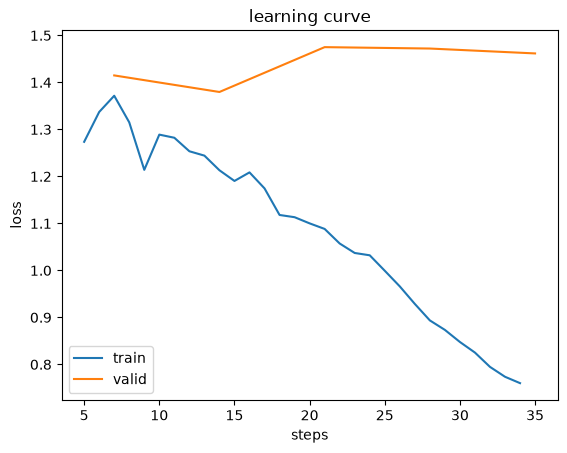

In [ ]:
learn.recorder.plot_loss()

## 8. Inference: Recognizing a Photograph Not Seen During Training

With `learn.predict()`, I pass an image to the model and receive:

1. the predicted class name;
2. its index in the class vocabulary;
3. a vector containing a score for each class.

The test photograph is loaded from `test/boletusTest.jpeg`, a directory separate from `dataset/`.

**Output of the saved run:** predicted class `Boletus_aereus`, score of approximately **65.7%**. This score reflects the model's preference among its available classes, **not** a 65.7% certainty that the identification is correct, nor a judgment about edibility.

The classifier is **closed-set**: even for a mushroom belonging to a different species, it may assign a high score to one of the four known classes.

In [ ]:
specie,_,probs = learn.predict(PILImage.create('test/boletusTest.jpeg'))
print(f'This is a: {specie}.')
print(f"Probability it's a {specie}: {probs[_]:.2f}")


This is a: Boletus_aereus.                                           
Probability it's a Boletus_aereus: 0.6570


## 9. Confusion Matrix: Which Species Are Mixed Up?

The **overall error rate** summarizes how many predictions are wrong, but does not identify which species the model confuses most often. The confusion matrix provides this detail.

In the plot, **rows** represent the true species and **columns** represent predicted species. The diagonal contains correct classifications; off-diagonal cells represent errors.

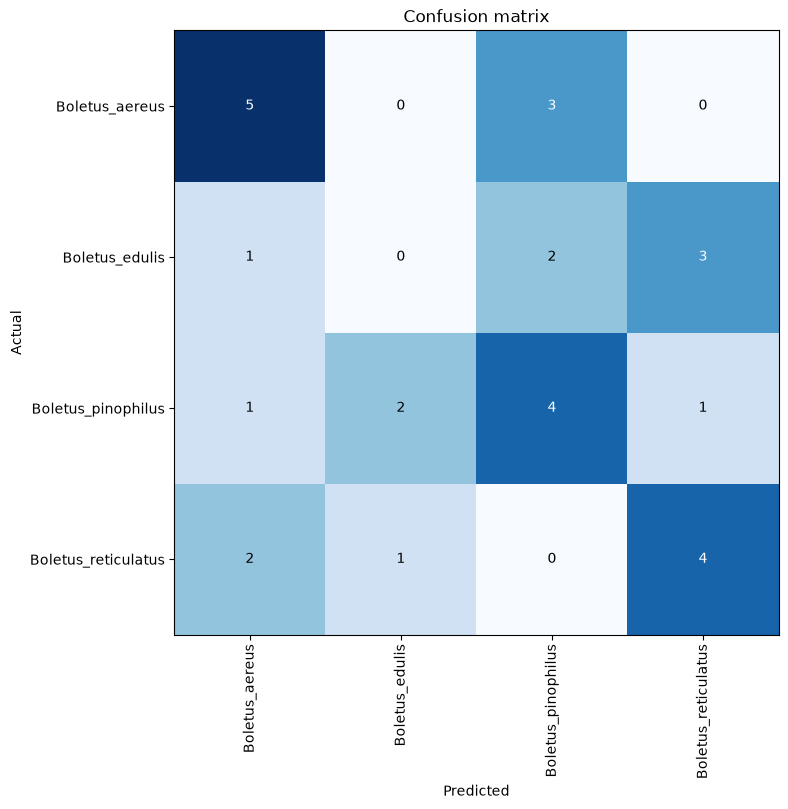

In [19]:
interp = ClassificationInterpretation.from_learner(learn)

interp.plot_confusion_matrix(figsize=(8, 8))

### Reading the Saved Confusion Matrix

In the recorded run, the validation set contains **29 images**. **13 out of 29** predictions are correct, corresponding to an accuracy of approximately **44.83%**.

| True species | Validation images | Correct | Observation |
|---|---:|---:|---|
| *Boletus aereus* | 8 | 5 | 3 images confused with *B. pinophilus* |
| *Boletus edulis* | 6 | **0** | No images classified correctly |
| *Boletus pinophilus* | 8 | 4 | Errors spread across the other three classes |
| *Boletus reticulatus* | 7 | 4 | Some images confused with *B. aereus* and *B. edulis* |

The most striking result is the difficulty with **B. edulis**. Before trying more complex architectures, I should review this class's photographs and labels, the amount of data, the similarities between species, and the presence of duplicates. The sample is still very small, so per-class percentages are unstable.

## 10. Analyzing the Most Significant Errors

`plot_top_losses()` displays the validation images that contribute most to the loss function, along with the predicted class and the label assigned by the dataset.

This analysis helps distinguish several possible issues:

- **Inaccurate labels:** a photograph may not depict the species indicated.
- **Image quality or composition:** the mushroom may be difficult to see, cropped, or photographed under challenging conditions.
- **Similarity between species:** some morphological features may look alike.
- **Artifacts and source patterns:** watermarks, recurring backgrounds, and catalog photographs can introduce undesirable shortcuts.

Images with high loss are not automatically mislabeled: each one must be reviewed individually and compared with reliable identifications.

> [!NOTE]
> **🖼️ Image panel — local error analysis**
>
> The next cell displays **6 high-loss images** and their corresponding classes. The embedded photographic output has been removed from this public version; the code and methodological interpretation remain available.
>
> To share sample images, choose only photographs with a compatible license and document the actual attribution.

In [ ]:
interp.plot_top_losses(6, nrows=2, figsize=(12, 8))

## Record of Reusable Images (To Be Completed)

If you decide to include actual photographs in the README or notebook outputs, maintain a record **for each published photograph**:

| Published file | Original source | Author | License and license URL | Modifications |
|---|---|---|---|---|
| *To be filled in after verification* | — | — | — | — |

Publish a photograph only after verifying that its rights permit the intended use and meeting all applicable requirements. For species identification, a suitable license does not guarantee that the label is correct: an independent taxonomic check is also needed.